# Ukraine Air Raid Alerts: Model Training & Evaluation Pipeline
> **Implementation aligned with PLAN.md (Phase 1 MVP)**
>
> **Task A (Active Alert):** Predict remaining duration ($P10, P50, P90$) and probability of alert ending within 15 / 30 / 60 minutes given elapsed time $t$.
>
> **Task B (Quiet Region):** Predict time until next alert ($P10, P50, P90$) and probability of alert starting within 1 / 3 / 6 hours given quiet elapsed time $t_{quiet}$.
>
> *Disclaimer: Statistical experiment for research and analysis. Never replaces official alert sirens or civil defense alerts.*


## 1. Setup & Imports


In [1]:
%load_ext autoreload
%autoreload 2

import sys
import os
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Add src to python path
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(project_root / "src"))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from lifelines import KaplanMeierFitter

# Import project modules
from alertpred.config import (
    RAW_DATA_PATH,
    MODELS_DIR,
    PROCESSED_DATA_DIR,
    REGION_MAPPING,
    OBLAST_NEIGHBORS,
    TASK_A_HORIZONS_MIN,
    TASK_B_HORIZONS_MIN,
)
from alertpred.data.cleaning import (
    load_raw_data,
    clean_alerts,
    build_gap_episodes,
    create_time_split,
)
from alertpred.ingestion.alerts_client import get_api_token
from alertpred.ingestion.backfill import fetch_all_region_histories, merge_with_existing
from alertpred.ingestion.live import get_live_alerts_status
from alertpred.features.builder import (
    sample_as_of_alert_moments,
    sample_as_of_gap_moments,
)
from alertpred.models.baseline import (
    EmpiricalConditionalBaseline,
    KaplanMeierBaseline,
)
from alertpred.models.quantile_lgbm import (
    LightGBMQuantileModel,
    LightGBMProbabilityModel,
    AlertPredictionPipeline,
)
from alertpred.evaluation.metrics import (
    evaluate_quantile_predictions,
    evaluate_classification_probabilities,
)

# Plot styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11

print(f"Project root: {project_root}")
print(f"Raw data path: {RAW_DATA_PATH} (exists: {RAW_DATA_PATH.exists()})")


Project root: /Users/allakovalcuk/Agentic_AI
Raw data path: /Users/allakovalcuk/Agentic_AI/data/raw/official_data_uk.csv (exists: True)


## 2. Data Ingestion & Cleaning
According to **PLAN.md Section 3.4**, raw alerts data requires:
1. Filtering by `level == 'oblast'` for macroscopic regional forecasting.
2. Parsing timestamps to UTC.
3. Filtering out technical glitches (< 1 minute) and unbounded anomalies.
4. Deduplicating overlapping intervals.
5. Mapping Ukrainian oblast names to standardized IDs.

The GitHub dataset (section 2.1) stops updating at some point in the past.
Sections 2.2-2.4 backfill the gap up to "now" using the alerts.in.ua API
and validate the backfilled data before merging it into the table the rest
of this notebook uses.


### 2.1 Original Historical Dataset (GitHub)


In [2]:
# Load raw data
df_raw = load_raw_data(RAW_DATA_PATH)
print(f"Total raw records: {len(df_raw):,}")
display(df_raw.head())


Total raw records: 299,275


,oblast,raion,hromada,level,started_at,finished_at,source
0,Вінницька область,NaN,NaN,oblast,2022-03-15 16:10:34+00:00,2022-03-15 16:50:07+00:00,official
1,Житомирська область,NaN,NaN,oblast,2022-03-15 16:11:25+00:00,2022-03-15 16:54:23+00:00,official
2,Черкаська область,Уманський район,Уманська територіальна громада,hromada,2022-03-15 16:11:50+00:00,2022-03-15 16:54:47+00:00,official
3,Миколаївська область,Первомайський район,м. Первомайськ та Первомайська територіальна г...,hromada,2022-03-15 16:14:46+00:00,2022-03-15 16:57:08+00:00,official
4,Кіровоградська область,NaN,NaN,oblast,2022-03-15 16:15:11+00:00,2022-03-15 16:54:52+00:00,official


In [3]:
# Clean alerts
df_alerts_github = clean_alerts(df_raw, filter_level='oblast', min_duration_sec=60)
print(f"Cleaned alert episodes: {len(df_alerts_github):,}")
print(f"Number of regions: {df_alerts_github['region_id'].nunique()}")
print(f"Date range: {df_alerts_github['started_at'].min().strftime('%Y-%m-%d')} to {df_alerts_github['started_at'].max().strftime('%Y-%m-%d')}")
display(df_alerts_github.head())


Cleaned alert episodes: 65,172


Number of regions: 24
Date range: 2022-03-15 to 2026-09-05


,oblast,raion,hromada,level,started_at,finished_at,source,duration_min,region_id,region_en
0,Черкаська область,NaN,NaN,oblast,2022-03-16 00:50:06+00:00,2022-03-16 04:42:26+00:00,official,232.333333,cherkasy,Cherkasy Oblast
1,Черкаська область,NaN,NaN,oblast,2022-03-17 01:33:50+00:00,2022-03-17 03:10:31+00:00,official,96.683333,cherkasy,Cherkasy Oblast
2,Черкаська область,NaN,NaN,oblast,2022-03-18 06:12:37+00:00,2022-03-18 06:56:54+00:00,official,44.283333,cherkasy,Cherkasy Oblast
3,Черкаська область,NaN,NaN,oblast,2022-03-18 08:50:19+00:00,2022-03-18 09:29:56+00:00,official,39.616667,cherkasy,Cherkasy Oblast
4,Черкаська область,NaN,NaN,oblast,2022-03-19 10:06:50+00:00,2022-03-19 10:58:17+00:00,official,51.450000,cherkasy,Cherkasy Oblast


### 2.2 Backfilling Recent Data via the alerts.in.ua API
[devs.alerts.in.ua](https://devs.alerts.in.ua/) exposes `/v1/regions/{uid}/alerts/month_ago.json`,
a rolling ~30-day history per oblast. We fetch it for all 27 oblasts and
reshape it into the same episode schema as the GitHub dataset so the two
can be concatenated.

**Caching & rate limits (per the docs):** this endpoint is limited to
2 requests/minute. `alertpred.ingestion.alerts_client` caches every response
to `data/cache/alerts_in_ua/` on disk and sends `If-Modified-Since` on
repeat calls, so **re-running this cell after the first time costs nothing**.
A cold run across all 27 oblasts takes roughly 13-14 minutes.

**Known limitation:** `month_ago` is the only documented lookback window -
it cannot reach further back than ~30 days. If the GitHub dataset's tail is
older than that, a gap will remain between the two sources (reported in 2.3).

Requires `ALERTS_IN_UA_TOKEN` in the environment or a `.env` file (copy
`.env.example` -> `.env` and fill in a token requested at the link above).
Without a token this cell is skipped and the notebook continues with the
GitHub-only dataset.


In [4]:
# Fetch per-oblast history from alerts.in.ua (or skip gracefully if no token is configured)
api_token = get_api_token()

if not api_token:
    print("No ALERTS_IN_UA_TOKEN found (env var or .env file).")
    print("Skipping the API backfill - continuing with the GitHub historical dataset only.")
    print("To enable: copy .env.example to .env and set your token (request one at https://devs.alerts.in.ua/).")
    df_alerts_api = pd.DataFrame()
else:
    print("Token found. Fetching ~last 30 days of history per oblast from alerts.in.ua")
    print("(cached on disk - a cold run takes ~13-14 min due to the API's 2 req/min history limit)\n")
    df_alerts_api = fetch_all_region_histories(period='month_ago')
    n_regions = df_alerts_api['region_id'].nunique() if not df_alerts_api.empty else 0
    print(f"\nFetched {len(df_alerts_api):,} completed episodes across {n_regions} regions from alerts.in.ua")
    if not df_alerts_api.empty:
        display(df_alerts_api.head())


No ALERTS_IN_UA_TOKEN found (env var or .env file).
Skipping the API backfill - continuing with the GitHub historical dataset only.
To enable: copy .env.example to .env and set your token (request one at https://devs.alerts.in.ua/).


### 2.3 Validating the Backfilled Data
Before trusting the new source, sanity-check it against the GitHub dataset:
coverage (does it actually close the gap?), any remaining uncovered gap,
and whether duration distributions are in the same ballpark (a large
divergence would indicate a parsing or schema mismatch, not a real
behavioral shift).


In [5]:
if df_alerts_api.empty:
    print("No API data fetched - nothing to validate.")
else:
    print(f"GitHub dataset date range  : {df_alerts_github['started_at'].min().strftime('%Y-%m-%d %H:%M')} to {df_alerts_github['started_at'].max().strftime('%Y-%m-%d %H:%M')}")
    print(f"alerts.in.ua date range    : {df_alerts_api['started_at'].min().strftime('%Y-%m-%d %H:%M')} to {df_alerts_api['started_at'].max().strftime('%Y-%m-%d %H:%M')}")

    gh_end = df_alerts_github['started_at'].max()
    api_start = df_alerts_api['started_at'].min()
    if api_start > gh_end:
        print(f"\nWARNING: uncovered gap between the two sources: {gh_end} to {api_start} ({(api_start - gh_end)})")
        print("(alerts.in.ua's history endpoint only exposes a rolling ~30-day window - see 2.2)")
    else:
        print(f"\nSources overlap by {gh_end - api_start} - the merge step (2.4) de-duplicates this overlap.")

    # Duration sanity check: distributions should be broadly comparable across sources
    compare = pd.concat([
        df_alerts_github.assign(_source='github')[['_source', 'duration_min']],
        df_alerts_api.assign(_source='alerts_in_ua')[['_source', 'duration_min']],
    ])
    print("\nDuration (minutes) by source, oblast-level episodes:")
    display(compare.groupby('_source')['duration_min'].describe().round(1))

    print("\nNew episodes per region (alerts.in.ua backfill):")
    display(df_alerts_api.groupby('region_en').size().sort_values(ascending=False).rename('new_episodes'))


No API data fetched - nothing to validate.


### 2.4 Merging into the Final Alerts Table
Concatenate both sources and de-duplicate on `(region_id, started_at)` -
the same rule `clean_alerts` uses internally - so an overlapping tail
produces no duplicate episodes. Everything from here on uses this merged
`df_alerts`.


In [6]:
df_alerts = merge_with_existing(df_alerts_github, df_alerts_api)
print(f"Final merged alert episodes: {len(df_alerts):,}  (GitHub: {len(df_alerts_github):,}, alerts.in.ua: {len(df_alerts_api):,})")
print(f"Number of regions: {df_alerts['region_id'].nunique()}")
print(f"Date range: {df_alerts['started_at'].min().strftime('%Y-%m-%d')} to {df_alerts['started_at'].max().strftime('%Y-%m-%d')}")
display(df_alerts.tail())


Final merged alert episodes: 65,172  (GitHub: 65,172, alerts.in.ua: 0)
Number of regions: 24
Date range: 2022-03-15 to 2026-09-05


,oblast,raion,hromada,level,started_at,finished_at,source,duration_min,region_id,region_en
65167,Житомирська область,NaN,NaN,oblast,2025-10-25 00:52:40+00:00,2025-10-25 01:28:47+00:00,official,36.116667,zhytomyr,Zhytomyr Oblast
65168,Житомирська область,NaN,NaN,oblast,2025-10-27 16:36:01+00:00,2025-10-27 16:51:58+00:00,official,15.950000,zhytomyr,Zhytomyr Oblast
65169,Житомирська область,NaN,NaN,oblast,2025-11-01 17:07:55+00:00,2025-11-01 17:41:12+00:00,official,33.283333,zhytomyr,Zhytomyr Oblast
65170,Житомирська область,NaN,NaN,oblast,2025-11-01 18:01:53+00:00,2025-11-01 18:42:50+00:00,official,40.950000,zhytomyr,Zhytomyr Oblast
65171,Житомирська область,NaN,NaN,oblast,2025-11-02 21:35:51+00:00,2025-11-02 22:07:07+00:00,official,31.266667,zhytomyr,Zhytomyr Oblast


In [7]:
# Build Task B Quiet Gap episodes (time between consecutive alerts per region)
df_gaps = build_gap_episodes(df_alerts)
print(f"Quiet gap episodes: {len(df_gaps):,}")
display(df_gaps.head())


Quiet gap episodes: 65,144


,region_id,region_en,gap_start,gap_end,gap_duration_min,prev_alert_duration_min
0,vinnytsia,Vinnytsia Oblast,2022-03-15 16:50:07+00:00,2022-03-15 16:52:30+00:00,2.383333,39.550000
1,zhytomyr,Zhytomyr Oblast,2022-03-15 16:54:23+00:00,2022-03-15 18:08:22+00:00,73.983333,42.966667
2,kirovohrad,Kirovohrad Oblast,2022-03-15 16:54:52+00:00,2022-03-15 18:11:07+00:00,76.250000,39.683333
3,chernihiv,Chernihiv Oblast,2022-03-15 17:02:48+00:00,2022-03-16 06:08:41+00:00,785.883333,32.516667
4,rivne,Rivne Oblast,2022-03-15 17:13:47+00:00,2022-03-15 23:48:56+00:00,395.150000,55.200000


### 2.5 Live Status Check (Current Information)
Demonstrates `get_live_alerts_status`, which now parses the real
`/v1/alerts/active.json` endpoint (real elapsed minutes per active region)
instead of the old placeholder values, and uses the merged table above to
compute real elapsed-quiet time for regions with no active alert. Falls
back to a demo snapshot if no token is configured or the API is
unreachable.


In [8]:
last_end_by_region = df_alerts.groupby('region_id')['finished_at'].max().to_dict()
live_status = get_live_alerts_status(last_alert_end_by_region=last_end_by_region)

print(f"Mode: {'Live API' if live_status['is_live_api'] else 'Demo Simulation (no token / API unreachable)'}")
print(f"Last updated: {live_status['last_updated']}")
print(f"Active regions: {live_status['total_active_regions']} / {len(live_status['regions'])}")

live_df = pd.DataFrame(live_status['regions']).T
display(live_df.sort_values('is_active', ascending=False))


Mode: Demo Simulation (no token / API unreachable)
Last updated: 2026-10-12 12:31:11 (Kyiv Time)
Active regions: 5 / 27


,is_active,elapsed_min,elapsed_quiet_min
kharkiv,True,42.0,0.0
dnipropetrovsk,True,20.0,0.0
donetsk,True,75.0,0.0
zaporizhzhia,True,30.0,0.0
sumy,True,15.0,0.0
kyiv_city,False,0.0,240.0
rivne,False,0.0,480.0
crimea,False,0.0,480.0
luhansk,False,0.0,480.0
kherson,False,0.0,480.0


## 3. Exploratory Data Analysis (EDA)
Comprehensive exploration of:
1. **Alert Frequency Across Oblasts:** Ranking, volume share, and monthly temporal intensity.
2. **Alert Duration Distributions (Mean vs. Median):** Skewness, dispersion, and diurnal hourly patterns.
3. **Spatial Context & Neighbor Co-Occurrence:** Simultaneous alert rates among direct neighbors, pairwise correlation heatmap, and propagation trajectory analysis.
4. **Quiet Gaps (Task B):** Inter-arrival quiet durations across frontline vs. rear oblasts.


,region_en,total_alerts,alerts_per_month,alerts_per_week,pct_national
0,Donetsk Oblast,6856,127.609295,29.347517,10.519855
1,Zaporizhzhia Oblast,6680,124.333443,28.594139,10.249801
2,Kharkiv Oblast,6491,120.815626,27.785113,9.959799
3,Dnipropetrovsk Oblast,5547,103.245151,23.744265,8.511324
4,Sumy Oblast,4069,75.735446,17.417597,6.243479
5,Poltava Oblast,3987,74.209197,17.066592,6.117658
6,Mykolaiv Oblast,3677,68.439232,15.739618,5.641993
7,Kherson Oblast,3571,66.466276,15.285879,5.479347
8,Kirovohrad Oblast,3341,62.185334,14.301350,5.126435
9,Chernihiv Oblast,2506,46.643654,10.727083,3.845210


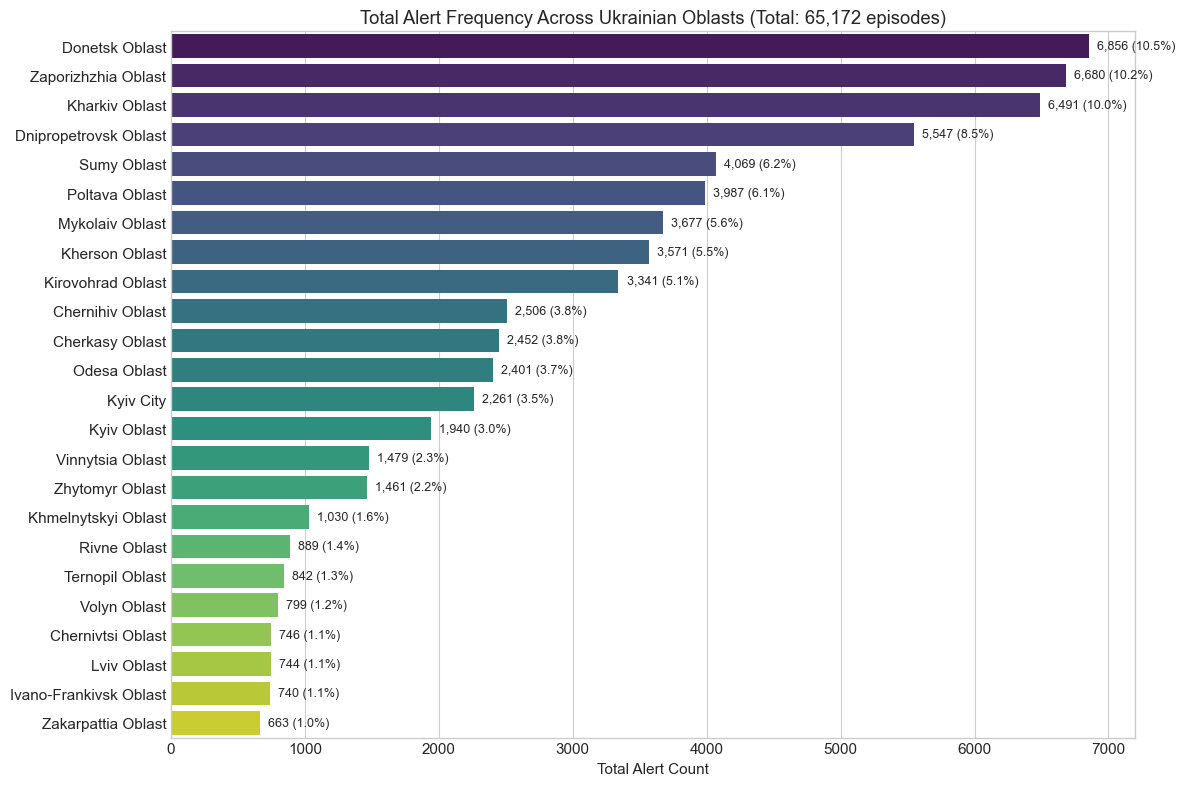

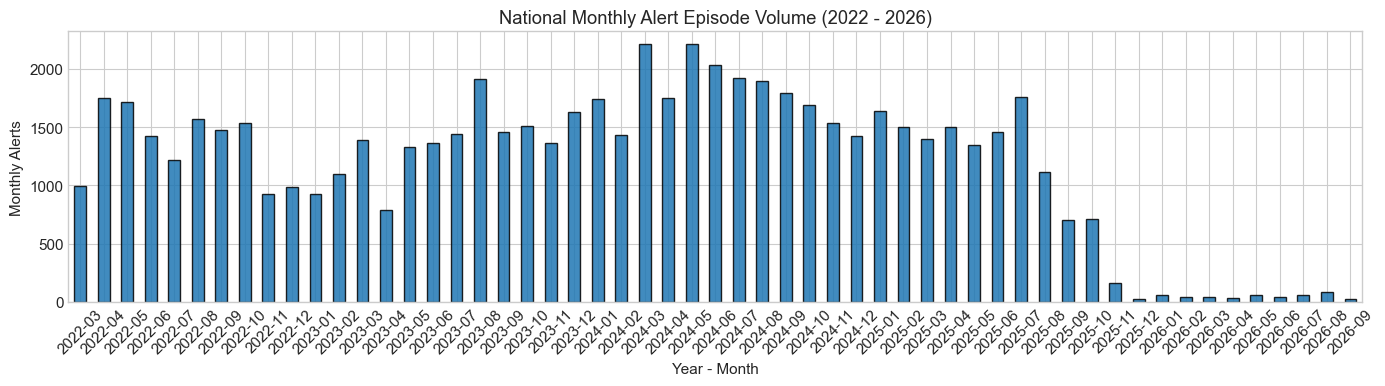

In [9]:
# 3.1 Alert Frequency Analysis by Oblast
total_days = (df_alerts['started_at'].max() - df_alerts['started_at'].min()).total_seconds() / (24 * 3600)
months_approx = total_days / 30.4375

freq_stats = df_alerts.groupby('region_en').size().reset_index(name='total_alerts')
freq_stats['alerts_per_month'] = freq_stats['total_alerts'] / months_approx
freq_stats['alerts_per_week'] = freq_stats['total_alerts'] / (total_days / 7.0)
freq_stats['pct_national'] = 100.0 * freq_stats['total_alerts'] / len(df_alerts)
freq_stats = freq_stats.sort_values(by='total_alerts', ascending=False).reset_index(drop=True)

display(freq_stats)

# Plot Horizontal Bar Chart of Alert Frequency
plt.figure(figsize=(12, 8))
sns.barplot(
    data=freq_stats,
    y='region_en',
    x='total_alerts',
    palette='viridis'
)
plt.title(f"Total Alert Frequency Across Ukrainian Oblasts (Total: {len(df_alerts):,} episodes)")
plt.xlabel("Total Alert Count")
plt.ylabel("")
for i, v in enumerate(freq_stats['total_alerts']):
    plt.text(v + 60, i, f"{v:,} ({freq_stats['pct_national'].iloc[i]:.1f}%)", va='center', fontsize=9)
plt.tight_layout()
plt.show()

# Monthly Timeline of Nationwide Alert Counts
df_alerts['year_month'] = df_alerts['started_at'].dt.to_period('M').astype(str)
monthly_counts = df_alerts.groupby('year_month').size()

plt.figure(figsize=(14, 4))
monthly_counts.plot(kind='bar', color='#1f77b4', edgecolor='black', alpha=0.85)
plt.title("National Monthly Alert Episode Volume (2022 - 2026)")
plt.xlabel("Year - Month")
plt.ylabel("Monthly Alerts")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


,count,mean_min,median_min,std_min,p10_min,p90_min,iqr_min,max_hours
region_en,,,,,,,,
Sumy Oblast,4069,117.67,52.22,159.47,19.48,275.93,114.17,28.35
Donetsk Oblast,6856,107.66,60.27,133.44,20.98,235.32,111.63,49.03
Chernihiv Oblast,2506,104.02,40.95,156.16,16.08,287.02,83.95,46.61
Kyiv Oblast,1940,102.03,47.25,131.48,16.58,258.17,94.00,15.86
Zhytomyr Oblast,1461,94.07,58.07,101.96,18.90,212.02,89.63,13.93
Kharkiv Oblast,6491,84.17,40.72,132.51,17.57,179.92,58.89,50.52
Khmelnytskyi Oblast,1030,82.45,60.02,73.61,19.97,184.38,80.20,10.98
Vinnytsia Oblast,1479,79.98,47.35,80.64,17.51,187.82,82.44,11.74
Poltava Oblast,3987,78.93,34.58,118.67,16.29,192.42,45.93,19.67


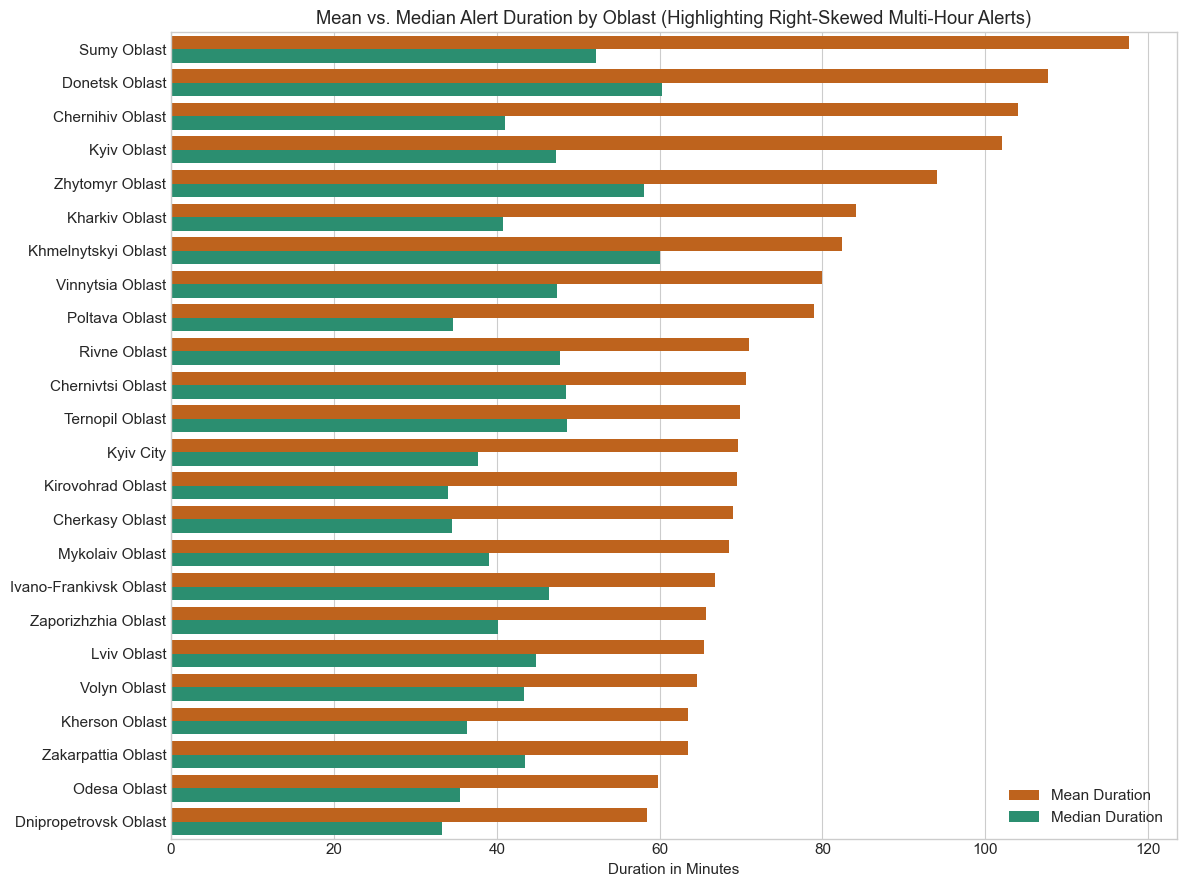

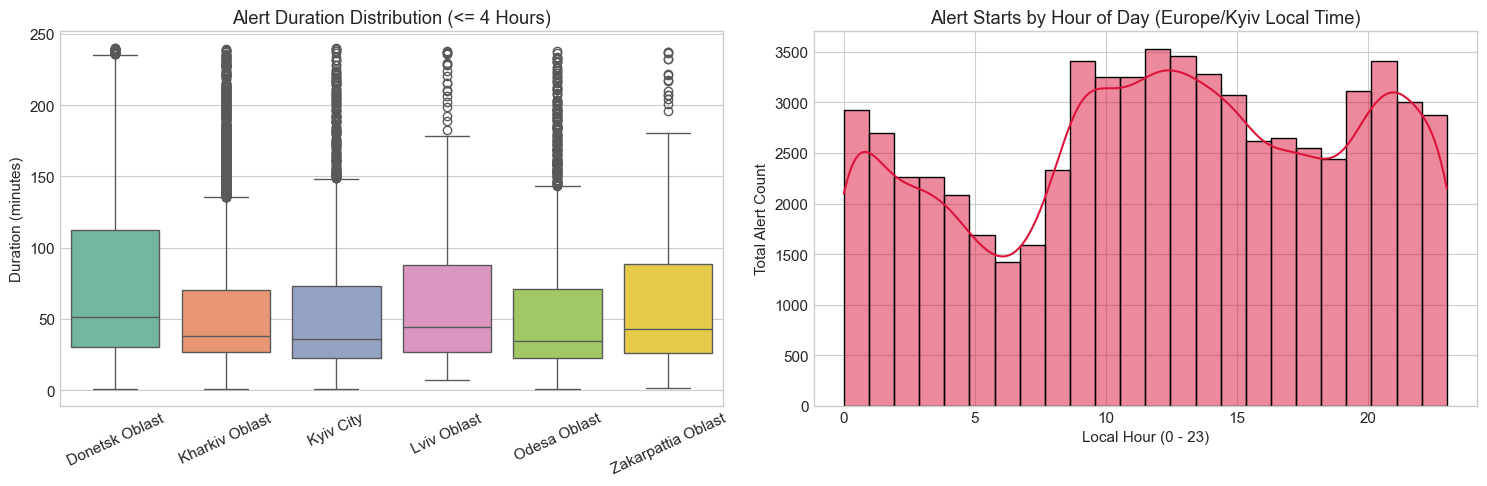

In [10]:
# 3.2 Duration Analysis: Mean vs. Median & Dispersion
duration_stats = df_alerts.groupby('region_en')['duration_min'].agg(
    count='count',
    mean_min='mean',
    median_min='median',
    std_min='std',
    p10_min=lambda s: np.percentile(s, 10),
    p90_min=lambda s: np.percentile(s, 90),
    iqr_min=lambda s: np.percentile(s, 75) - np.percentile(s, 25),
    max_hours=lambda s: s.max() / 60.0
).sort_values(by='mean_min', ascending=False)

display(duration_stats.round(2))

# Side-by-Side Comparison: Mean vs. Median Duration
dur_plot_df = duration_stats.reset_index().melt(
    id_vars='region_en',
    value_vars=['mean_min', 'median_min'],
    var_name='Metric',
    value_name='Duration (min)'
)
dur_plot_df['Metric'] = dur_plot_df['Metric'].map({'mean_min': 'Mean Duration', 'median_min': 'Median Duration'})

plt.figure(figsize=(12, 9))
sns.barplot(
    data=dur_plot_df,
    y='region_en',
    x='Duration (min)',
    hue='Metric',
    palette=['#d95f02', '#1b9e77']
)
plt.title("Mean vs. Median Alert Duration by Oblast (Highlighting Right-Skewed Multi-Hour Alerts)")
plt.xlabel("Duration in Minutes")
plt.ylabel("")
plt.legend(title="")
plt.tight_layout()
plt.show()

# Boxplot across Macro-Regions & Diurnal Hour-of-Day Pattern
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sample_regions = ['Donetsk Oblast', 'Kharkiv Oblast', 'Kyiv City', 'Odesa Oblast', 'Lviv Oblast', 'Zakarpattia Oblast']
sns.boxplot(
    data=df_alerts[df_alerts['region_en'].isin(sample_regions) & (df_alerts['duration_min'] <= 240)],
    x='region_en',
    y='duration_min',
    palette='Set2',
    ax=axes[0]
)
axes[0].set_title("Alert Duration Distribution (<= 4 Hours)")
axes[0].set_ylabel("Duration (minutes)")
axes[0].set_xlabel("")
axes[0].tick_params(axis='x', rotation=25)

# Diurnal Pattern (Hour of Day in Europe/Kyiv Local Time)
df_alerts['start_kyiv_hour'] = df_alerts['started_at'].dt.tz_convert('Europe/Kyiv').dt.hour
sns.histplot(df_alerts['start_kyiv_hour'], bins=24, kde=True, color='crimson', ax=axes[1])
axes[1].set_title("Alert Starts by Hour of Day (Europe/Kyiv Local Time)")
axes[1].set_xlabel("Local Hour (0 - 23)")
axes[1].set_ylabel("Total Alert Count")
plt.tight_layout()
plt.show()


,region_en,active_hours,co_active_neighbor_hours,pct_neighbor_simultaneous,neighbor_count
0,Chernivtsi Oblast,1614,1611,99.814126,4
1,Poltava Oblast,8838,8814,99.728445,7
2,Ivano-Frankivsk Oblast,1548,1542,99.612403,4
3,Zakarpattia Oblast,1349,1342,99.481097,2
4,Rivne Oblast,1932,1919,99.327122,4
5,Dnipropetrovsk Oblast,10180,10110,99.312377,7
6,Lviv Oblast,1538,1526,99.219766,5
7,Ternopil Oblast,1809,1793,99.115533,5
8,Vinnytsia Oblast,3412,3377,98.974209,7
9,Kirovohrad Oblast,6960,6888,98.965517,6


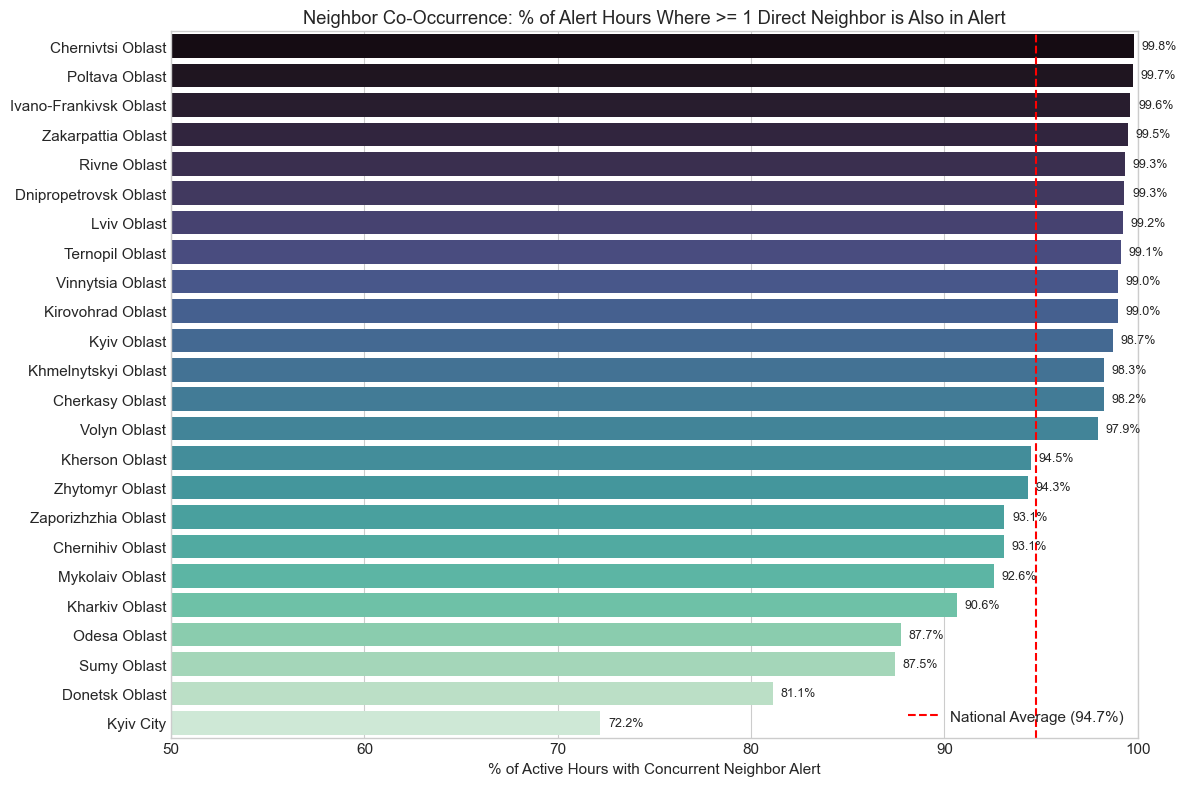

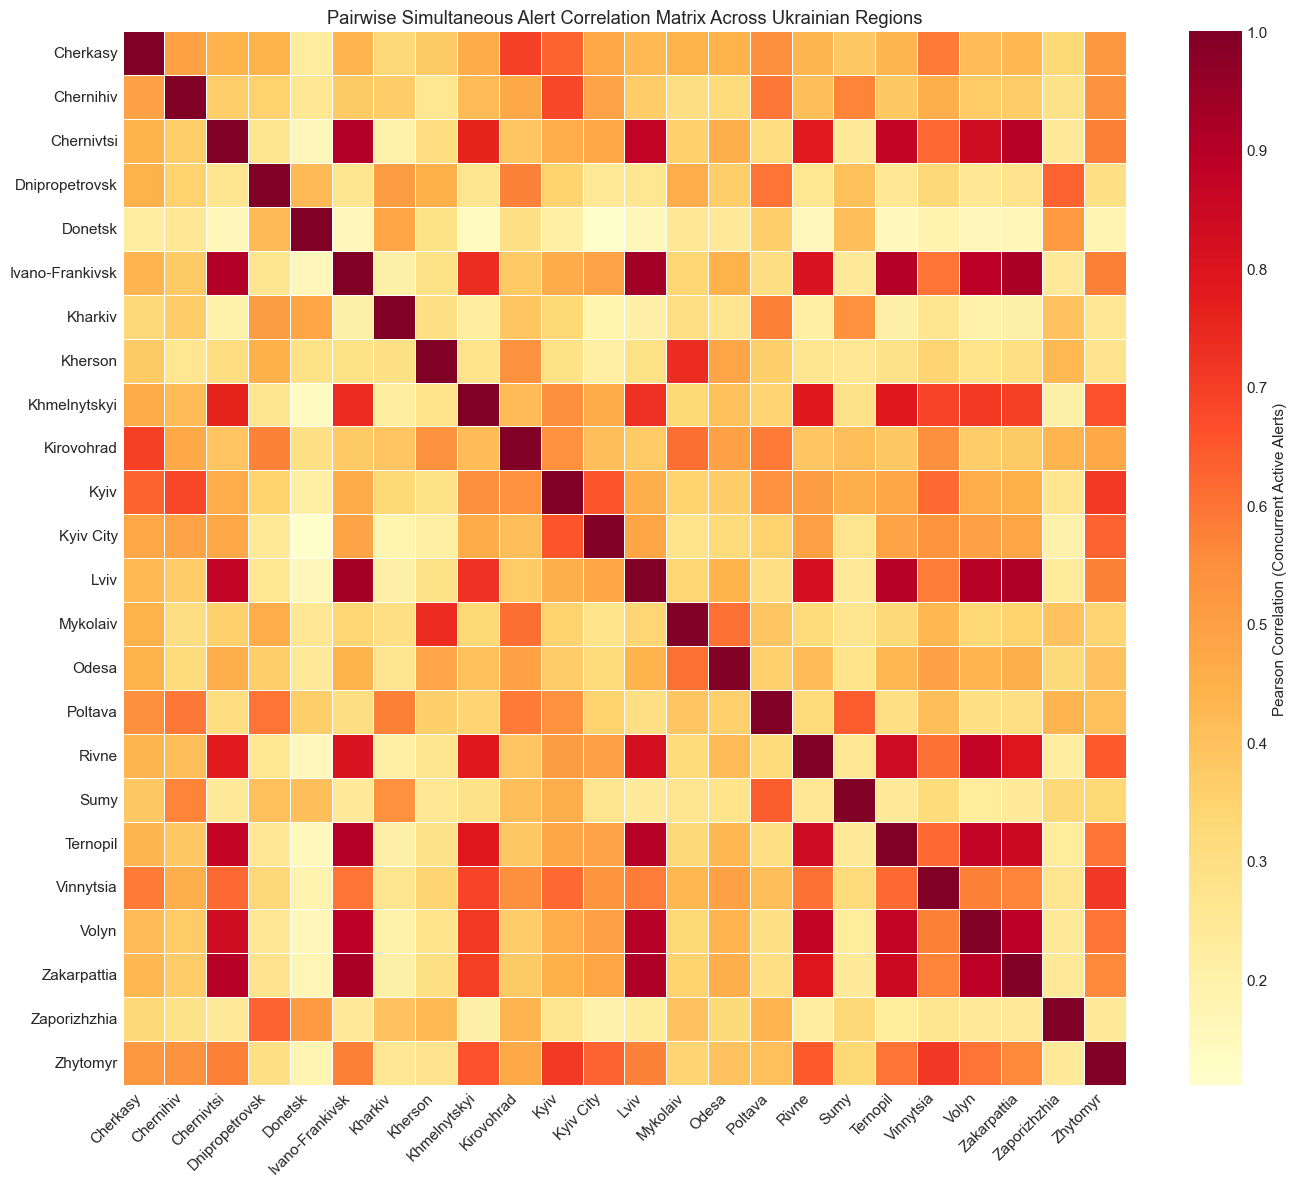

In [11]:
# 3.3 Spatial Context: Simultaneous Alerts in Neighboring Oblasts
start_time = df_alerts['started_at'].min().floor('h')
end_time = df_alerts['finished_at'].max().ceil('h')
hourly_grid = pd.date_range(start_time, end_time, freq='1h', tz='UTC')

region_ids = sorted(df_alerts['region_id'].unique())
reg_to_idx = {r: i for i, r in enumerate(region_ids)}
matrix = np.zeros((len(hourly_grid), len(region_ids)), dtype=bool)

for _, row in df_alerts.iterrows():
    c = reg_to_idx[row['region_id']]
    s_idx = max(0, int((row['started_at'] - start_time).total_seconds() // 3600))
    e_idx = min(len(hourly_grid), int((row['finished_at'] - start_time).total_seconds() // 3600) + 1)
    matrix[s_idx:e_idx, c] = True

# Compute Simultaneous Alert Percentage with Direct Neighbors
neighbor_sim_results = []
for reg in region_ids:
    c = reg_to_idx[reg]
    reg_active = matrix[:, c]
    total_active_hours = int(reg_active.sum())
    
    direct_neighbors = [n for n in OBLAST_NEIGHBORS.get(reg, []) if n in reg_to_idx]
    if not direct_neighbors or total_active_hours == 0:
        continue
    
    n_indices = [reg_to_idx[n] for n in direct_neighbors]
    any_neighbor_active = matrix[:, n_indices].any(axis=1)
    co_active_hours = int((reg_active & any_neighbor_active).sum())
    
    reg_en = df_alerts[df_alerts['region_id'] == reg]['region_en'].iloc[0]
    
    neighbor_sim_results.append({
        'region_id': reg,
        'region_en': reg_en,
        'active_hours': total_active_hours,
        'co_active_neighbor_hours': co_active_hours,
        'pct_neighbor_simultaneous': 100.0 * co_active_hours / total_active_hours,
        'neighbor_count': len(direct_neighbors),
    })

df_neighbor_sim = pd.DataFrame(neighbor_sim_results).sort_values('pct_neighbor_simultaneous', ascending=False).reset_index(drop=True)
display(df_neighbor_sim[['region_en', 'active_hours', 'co_active_neighbor_hours', 'pct_neighbor_simultaneous', 'neighbor_count']])

# Bar Plot: Neighbor Co-Occurrence Percentage
plt.figure(figsize=(12, 8))
sns.barplot(
    data=df_neighbor_sim,
    y='region_en',
    x='pct_neighbor_simultaneous',
    palette='mako'
)
mean_sim = df_neighbor_sim['pct_neighbor_simultaneous'].mean()
plt.axvline(x=mean_sim, color='red', linestyle='--', label=f"National Average ({mean_sim:.1f}%)")
plt.title("Neighbor Co-Occurrence: % of Alert Hours Where >= 1 Direct Neighbor is Also in Alert")
plt.xlabel("% of Active Hours with Concurrent Neighbor Alert")
plt.ylabel("")
plt.xlim(50, 100)
plt.legend(loc='lower right')
for i, v in enumerate(df_neighbor_sim['pct_neighbor_simultaneous']):
    plt.text(v + 0.4, i, f"{v:.1f}%", va='center', fontsize=9)
plt.tight_layout()
plt.show()

# Pairwise Correlation Heatmap Across All 24 Regions
id_to_en = df_alerts.drop_duplicates('region_id').set_index('region_id')['region_en'].to_dict()
clean_names = [id_to_en.get(r, r).replace(' Oblast', '').replace(' Autonomous Republic of ', '') for r in region_ids]
df_hourly = pd.DataFrame(matrix.astype(int), columns=clean_names)
corr_matrix = df_hourly.corr()

plt.figure(figsize=(14, 12))
sns.heatmap(
    corr_matrix,
    cmap='YlOrRd',
    annot=False,
    linewidths=0.5,
    cbar_kws={'label': 'Pearson Correlation (Concurrent Active Alerts)'}
)
plt.title("Pairwise Simultaneous Alert Correlation Matrix Across Ukrainian Regions")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


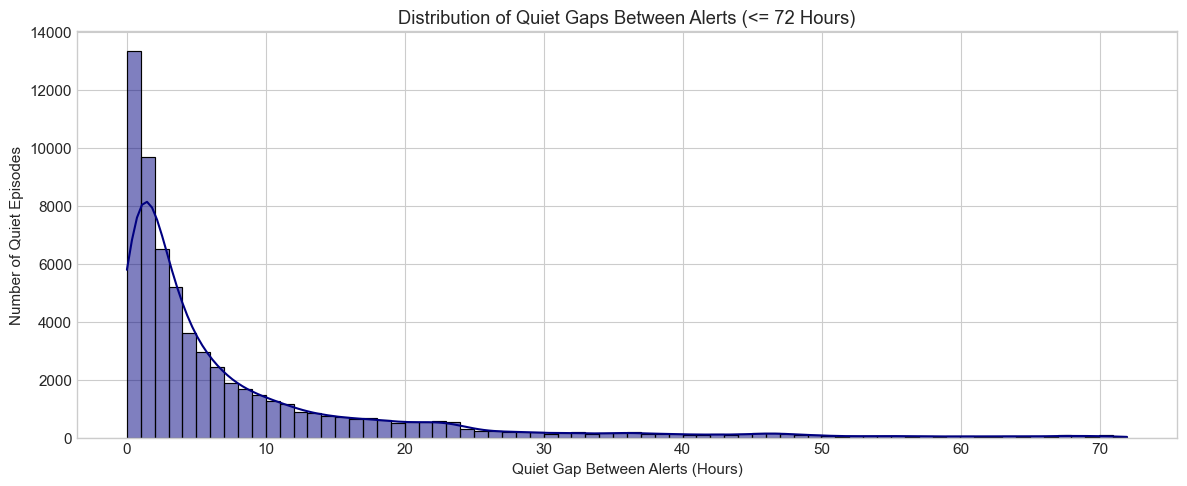

Median Quiet Hours Between Alerts by Oblast (Frontline vs. Rear Oblasts):


,region_en,episode_count,median_quiet_hours,p25_quiet_hours,p75_quiet_hours
0,Donetsk Oblast,6855,1.815556,0.757083,3.395000
1,Kharkiv Oblast,6489,1.856667,0.718333,4.025556
2,Sumy Oblast,4067,2.290278,0.907639,6.151667
3,Zaporizhzhia Oblast,6679,2.315833,0.907917,4.908333
4,Dnipropetrovsk Oblast,5546,2.681667,0.967708,6.218750
5,Poltava Oblast,3985,3.615000,1.320833,8.188611
6,Kherson Oblast,3569,3.835278,1.456389,9.187500
7,Mykolaiv Oblast,3676,4.194722,1.497500,10.035347
8,Kirovohrad Oblast,3340,4.803750,1.730625,10.652431
9,Chernihiv Oblast,2505,5.280000,1.867500,12.745556


In [12]:
# 3.4 Inter-Alert Quiet Gap Distribution (Task B)
plt.figure(figsize=(12, 5))
gap_hours = df_gaps['gap_duration_min'] / 60.0

sns.histplot(gap_hours[gap_hours <= 72], bins=72, color='navy', kde=True)
plt.title("Distribution of Quiet Gaps Between Alerts (<= 72 Hours)")
plt.xlabel("Quiet Gap Between Alerts (Hours)")
plt.ylabel("Number of Quiet Episodes")
plt.tight_layout()
plt.show()

gap_summary = df_gaps.groupby('region_en')['gap_duration_min'].agg(
    episode_count='count',
    median_quiet_hours=lambda s: s.median() / 60.0,
    p25_quiet_hours=lambda s: np.percentile(s, 25) / 60.0,
    p75_quiet_hours=lambda s: np.percentile(s, 75) / 60.0,
).sort_values(by='median_quiet_hours').reset_index()

print("Median Quiet Hours Between Alerts by Oblast (Frontline vs. Rear Oblasts):")
display(gap_summary)


## 4. Chronological Train / Test Split
**PLAN.md Section 5.6:** *Never shuffle time series data.* We perform a strict point-in-time split (e.g. 80% train, 20% test on recent months) to prevent data leakage.


In [13]:
# Split alerts (Task A) and gaps (Task B)
alerts_train, alerts_test = create_time_split(df_alerts, timestamp_col='started_at', train_ratio=0.80)
gaps_train, gaps_test = create_time_split(df_gaps, timestamp_col='gap_start', train_ratio=0.80)

split_date = alerts_test['started_at'].min()
print(f"Train/Test split cutoff timestamp: {split_date}")
print(f"Task A (Alerts): Train = {len(alerts_train):,}, Test = {len(alerts_test):,}")
print(f"Task B (Gaps):   Train = {len(gaps_train):,}, Test = {len(gaps_test):,}")


Train/Test split cutoff timestamp: 2025-01-13 12:47:50+00:00
Task A (Alerts): Train = 52,137, Test = 13,035
Task B (Gaps):   Train = 52,115, Test = 13,029


## 5. Baseline Models (PLAN.md Section 5.1)
The core insight: When an alert has already lasted $t$ minutes, what is the conditional distribution of remaining time:
$$P(\text{remaining} \le \Delta \mid \text{duration} > t)$$
We implement:
1. **Empirical Conditional Quantile Baseline**: Non-parametric conditional quantiles ($P10, P50, P90$) and probabilities.
2. **Kaplan-Meier Survival Baseline**: Survival curve $S(t) = P(D > t)$ with conditional probability:
$$P(\text{ends within } \Delta \mid D > t) = 1 - \frac{S(t + \Delta)}{S(t)}$$


In [14]:
# 5.1 Fit Empirical Baseline on Training Data
baseline_empirical = EmpiricalConditionalBaseline().fit(alerts_train)

# Fit Kaplan-Meier baseline
km_baseline = KaplanMeierBaseline().fit(alerts_train)

# Compare predictions for Kyiv City when alert has lasted 30 minutes
pred_kyiv_30m = baseline_empirical.predict_remaining('kyiv_city', elapsed_min=30.0)
km_prob_30m_end_in_15m = km_baseline.predict_survival_prob('kyiv_city', elapsed_min=30.0, delta_min=15.0)

print("Empirical Baseline Prediction (Kyiv City, elapsed = 30m):")
print(f"  Predicted remaining median: {pred_kyiv_30m['p50']:.1f} min")
print(f"  Uncertainty range [P10, P90]: [{pred_kyiv_30m['p10']:.1f}, {pred_kyiv_30m['p90']:.1f}] min")
print(f"  Probability ends within 15 min: {pred_kyiv_30m['probabilities']['within_15m']:.1%}")
print(f"  Kaplan-Meier prob ends within 15 min: {km_prob_30m_end_in_15m:.1%}")


Empirical Baseline Prediction (Kyiv City, elapsed = 30m):
  Predicted remaining median: 37.8 min
  Uncertainty range [P10, P90]: [3.5, 143.2] min
  Probability ends within 15 min: 29.7%
  Kaplan-Meier prob ends within 15 min: 29.7%


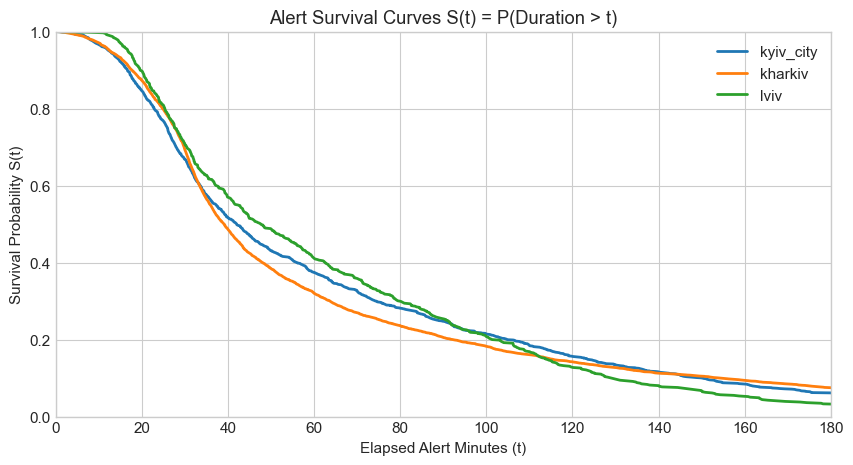

In [15]:
# 5.2 Plot Kaplan-Meier Survival Curves for Selected Regions
plt.figure(figsize=(10, 5))
for reg_id in ['kyiv_city', 'kharkiv', 'lviv']:
    kmf = km_baseline.kmfs[reg_id]
    plt.plot(kmf.survival_function_.index, kmf.survival_function_['KM_estimate'], label=reg_id, lw=2)

plt.title("Alert Survival Curves S(t) = P(Duration > t)")
plt.xlabel("Elapsed Alert Minutes (t)")
plt.ylabel("Survival Probability S(t)")
plt.xlim(0, 180)
plt.ylim(0, 1)
plt.legend()
plt.show()


## 6. Feature Engineering & As-Of Moment Sampling
**PLAN.md Section 5.6:** In production, users query the app at arbitrary moments *during* an ongoing alert.
To train models accurately:
- We sample "as-of" snapshot moments $t \in [0, 5, 10, 15, 20, 30, 45, 60, 90, 120]$ inside each historical alert episode.
- At snapshot $t$:
  - Feature: $elapsed\_min = t$
  - Target: $remaining\_min = \text{total duration} - t$
  - Classification Targets: $ends\_within\_15m, ends\_within\_30m, ends\_within\_60m$
- We compute point-in-time cyclical time features (hour sine/cosine, weekday, month, weekend).


In [16]:
# Sample as-of snapshots for Task A
train_a_samples = sample_as_of_alert_moments(alerts_train)
test_a_samples = sample_as_of_alert_moments(alerts_test)

# Sample as-of snapshots for Task B
train_b_samples = sample_as_of_gap_moments(gaps_train)
test_b_samples = sample_as_of_gap_moments(gaps_test)

print(f"Task A (Alert Duration) Snapshots -> Train: {len(train_a_samples):,}, Test: {len(test_a_samples):,}")
print(f"Task B (Quiet Gaps) Snapshots     -> Train: {len(train_b_samples):,}, Test: {len(test_b_samples):,}")
display(train_a_samples.head())


Task A (Alert Duration) Snapshots -> Train: 344,418, Test: 91,027
Task B (Quiet Gaps) Snapshots     -> Train: 230,895, Test: 56,588


,region_id,region_en,as_of_ts,start_ts,elapsed_min,total_duration_min,target_remaining_min,target_ends_within_15m,target_ends_within_30m,target_ends_within_60m,hour_sin,hour_cos,dow_sin,dow_cos,is_weekend,month
0,vinnytsia,Vinnytsia Oblast,2022-03-15 16:10:34+00:00,2022-03-15 16:10:34+00:00,0.0,39.55,39.55,0,0,1,-0.887011,-0.461749,0.781831,0.62349,0,3
1,vinnytsia,Vinnytsia Oblast,2022-03-15 16:15:34+00:00,2022-03-15 16:10:34+00:00,5.0,39.55,34.55,0,0,1,-0.896873,-0.442289,0.781831,0.62349,0,3
2,vinnytsia,Vinnytsia Oblast,2022-03-15 16:20:34+00:00,2022-03-15 16:10:34+00:00,10.0,39.55,29.55,0,1,1,-0.906308,-0.422618,0.781831,0.62349,0,3
3,vinnytsia,Vinnytsia Oblast,2022-03-15 16:25:34+00:00,2022-03-15 16:10:34+00:00,15.0,39.55,24.55,0,1,1,-0.915311,-0.402747,0.781831,0.62349,0,3
4,vinnytsia,Vinnytsia Oblast,2022-03-15 16:30:34+00:00,2022-03-15 16:10:34+00:00,20.0,39.55,19.55,0,1,1,-0.923880,-0.382683,0.781831,0.62349,0,3


## 7. Machine Learning Models: LightGBM Quantile & Probability
We train:
1. **LightGBM Quantile Regressors** with $\alpha \in [0.10, 0.50, 0.90]$ to predict remaining duration and intervals.
2. **LightGBM Binary Classifiers** to output calibrated probabilities:
   - Task A: $P(\text{ends within } 15, 30, 60 \text{ min})$
   - Task B: $P(\text{starts within } 1, 3, 6 \text{ hours})$


In [17]:
# Initialize end-to-end pipeline
pipeline = AlertPredictionPipeline()

# Train Task A (Alert Remaining Duration)
print("--> Training Task A Models...")
pipeline.fit_task_a(train_a_samples)

# Train Task B (Quiet Gap Until Next Alert)
print("--> Training Task B Models...")
pipeline.fit_task_b(train_b_samples)

print("All models successfully trained!")


--> Training Task A Models...
Training Task A (Remaining alert duration quantiles P10/P50/P90)...


Training Task A (Probability of alert end within 15/30/60m)...


--> Training Task B Models...
Training Task B (Quiet gap until next alert quantiles P10/P50/P90)...


Training Task B (Probability of next alert within 1h/3h/6h)...


All models successfully trained!


## 8. Model Evaluation & Benchmark Comparison
Comparing **LightGBM** vs. **Empirical Baseline** on the held-out test split:
- **MAE / Median AE:** point accuracy in minutes
- **Pinball Loss:** quantile calibration
- **P10-P90 Coverage:** fraction of true outcomes inside the predicted interval (target: ~80%)
- **Brier Score & Accuracy:** probability calibration


In [18]:
# Evaluate Task A Baseline
baseline_preds = baseline_empirical.predict_batch(test_a_samples, elapsed_col='elapsed_min')
eval_baseline_a = evaluate_quantile_predictions(
    y_true=test_a_samples['target_remaining_min'].values,
    p10=baseline_preds['baseline_p10'].values,
    p50=baseline_preds['baseline_p50'].values,
    p90=baseline_preds['baseline_p90'].values
)

# Evaluate Task A LightGBM
lgb_preds_a = pipeline.task_a_quantile.predict(test_a_samples)
eval_lgb_a = evaluate_quantile_predictions(
    y_true=test_a_samples['target_remaining_min'].values,
    p10=lgb_preds_a['pred_p10'].values,
    p50=lgb_preds_a['pred_p50'].values,
    p90=lgb_preds_a['pred_p90'].values
)

# Benchmark Comparison Table
comparison_df = pd.DataFrame([
    {"Model": "Empirical Baseline", **eval_baseline_a},
    {"Model": "LightGBM Quantile", **eval_lgb_a},
])
display(comparison_df[['Model', 'mae_p50_min', 'median_ae_p50_min', 'coverage_p10_p90', 'mean_pinball_loss']])


,Model,mae_p50_min,median_ae_p50_min,coverage_p10_p90,mean_pinball_loss
0,Empirical Baseline,102.995040,34.858333,0.645874,36.641273
1,LightGBM Quantile,100.705277,36.775415,0.613697,36.007482


In [19]:
# Evaluate Probability Classifiers for Task A (Ends within 15/30/60 min)
lgb_probs_a = pipeline.task_a_probs.predict_proba(test_a_samples)
prob_evals = []
for h in [15, 30, 60]:
    metrics = evaluate_classification_probabilities(
        y_true_binary=test_a_samples[f'target_ends_within_{h}m'].values,
        y_prob=lgb_probs_a[f'prob_ends_within_{h}m'].values
    )
    metrics['Horizon'] = f"Ends within {h}m"
    prob_evals.append(metrics)

display(pd.DataFrame(prob_evals)[['Horizon', 'accuracy', 'brier_score', 'roc_auc']])


,Horizon,accuracy,brier_score,roc_auc
0,Ends within 15m,0.815725,0.139787,0.695245
1,Ends within 30m,0.693388,0.208423,0.707247
2,Ends within 60m,0.559658,0.241741,0.734039


## 9. Interactive Scenario Explorer
Simulating live queries that will appear in the Streamlit web app.


In [20]:
# 9.1 Scenario: Active Alert in Kyiv running for 35 minutes
pred_active_kyiv = pipeline.predict_active_alert(
    region_id='kyiv_city',
    elapsed_min=35.0,
    timestamp=pd.Timestamp.now(tz='UTC')
)

print("=" * 60)
print("SCENARIO 1: ACTIVE ALERT IN KYIV (Elapsed: 35 minutes)")
print("=" * 60)
print(f"Predicted Remaining Duration (Median P50): {pred_active_kyiv['predicted_remaining_median_min']} min")
print(f"Predicted Uncertainty Range [P10, P90]   : {pred_active_kyiv['predicted_range_p10_p90_min']} min")
print("Probabilities:")
for k, v in pred_active_kyiv['probabilities'].items():
    print(f"  • {k}: {v:.1%}")


SCENARIO 1: ACTIVE ALERT IN KYIV (Elapsed: 35 minutes)
Predicted Remaining Duration (Median P50): 39.6 min
Predicted Uncertainty Range [P10, P90]   : [2.9, 104.2] min
Probabilities:
  • prob_ends_within_15m: 31.3%
  • prob_ends_within_30m: 43.4%
  • prob_ends_within_60m: 64.6%


In [21]:
# 9.2 Scenario: Quiet Region in Lviv with no alert for 4 hours
pred_quiet_lviv = pipeline.predict_quiet_region(
    region_id='lviv',
    elapsed_quiet_min=240.0,
    prev_alert_duration_min=40.0,
    timestamp=pd.Timestamp.now(tz='UTC')
)

print("=" * 60)
print("SCENARIO 2: QUIET PERIOD IN LVIV (Quiet for: 4 hours)")
print("=" * 60)
print(f"Predicted Gap to Next Alert (Median P50): {pred_quiet_lviv['predicted_next_alert_gap_median_min']} min ({pred_quiet_lviv['predicted_next_alert_gap_median_min']/60:.1f} hrs)")
print(f"Predicted Uncertainty Range [P10, P90]  : {pred_quiet_lviv['predicted_range_p10_p90_min']} min")
print("Probabilities:")
for k, v in pred_quiet_lviv['probabilities'].items():
    print(f"  • {k}: {v:.1%}")


SCENARIO 2: QUIET PERIOD IN LVIV (Quiet for: 4 hours)
Predicted Gap to Next Alert (Median P50): 2207.3 min (36.8 hrs)
Predicted Uncertainty Range [P10, P90]  : [362.1, 5147.0] min
Probabilities:
  • prob_starts_within_1h: 2.7%
  • prob_starts_within_3h: 6.7%
  • prob_starts_within_6h: 10.9%


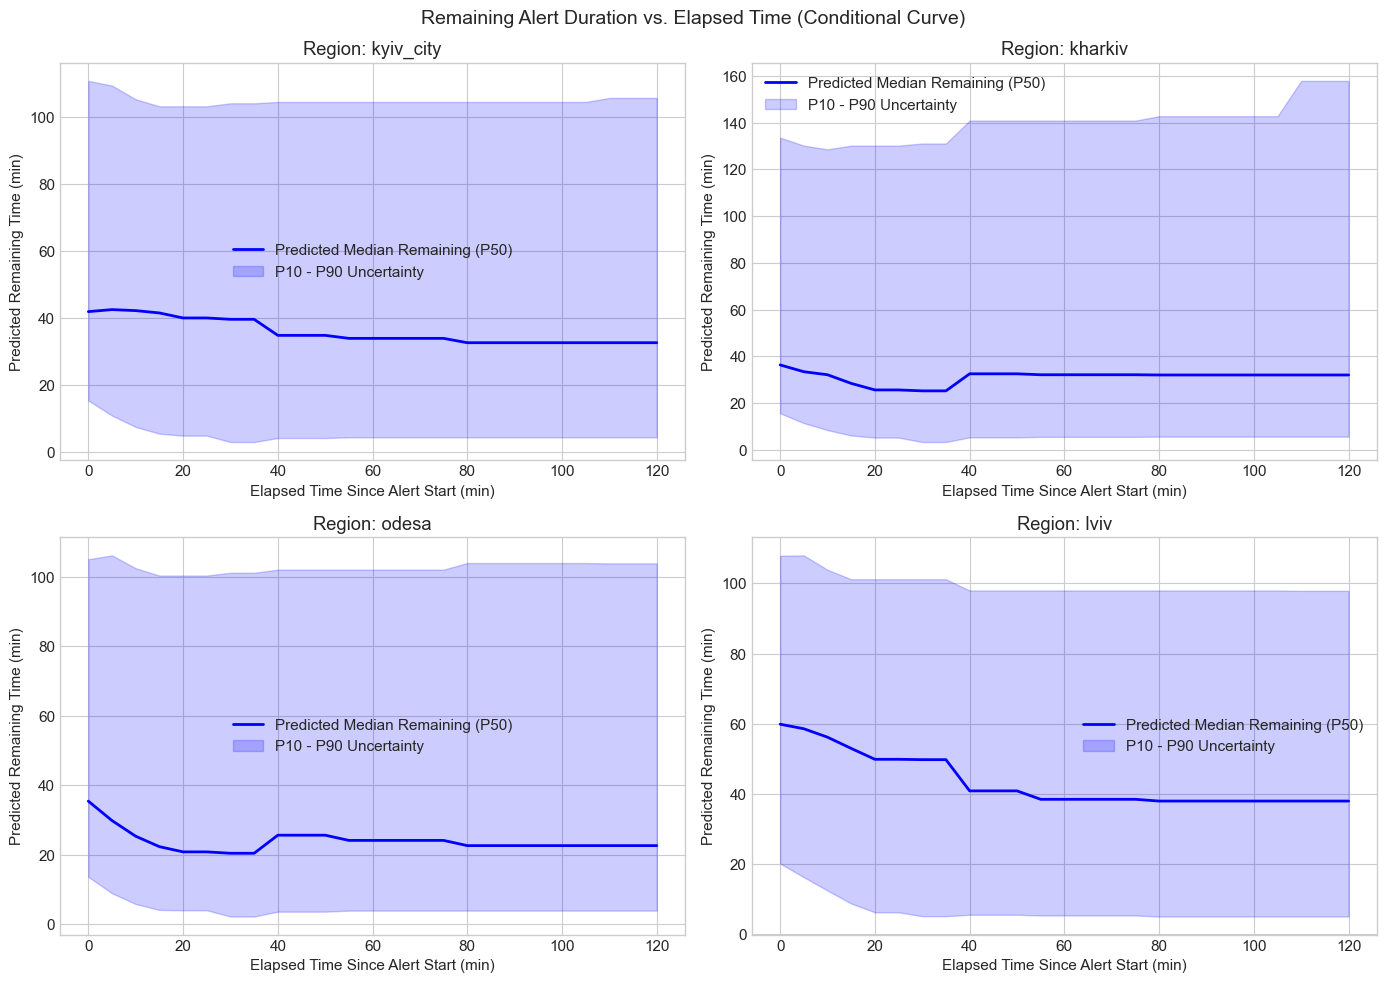

In [22]:
# 9.3 Visualizing Predicted Remaining Duration vs. Elapsed Time for Multiple Oblasts
elapsed_grid = np.linspace(0, 120, 25)
regions_to_plot = ['kyiv_city', 'kharkiv', 'odesa', 'lviv']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for idx, reg in enumerate(regions_to_plot):
    p50_list, p10_list, p90_list = [], [], []
    for t in elapsed_grid:
        res = pipeline.predict_active_alert(reg, elapsed_min=t)
        p50_list.append(res['predicted_remaining_median_min'])
        p10_list.append(res['predicted_range_p10_p90_min'][0])
        p90_list.append(res['predicted_range_p10_p90_min'][1])
        
    ax = axes[idx]
    ax.plot(elapsed_grid, p50_list, 'b-', label='Predicted Median Remaining (P50)', lw=2)
    ax.fill_between(elapsed_grid, p10_list, p90_list, color='blue', alpha=0.2, label='P10 - P90 Uncertainty')
    ax.set_title(f"Region: {reg}")
    ax.set_xlabel("Elapsed Time Since Alert Start (min)")
    ax.set_ylabel("Predicted Remaining Time (min)")
    ax.legend()
    
plt.suptitle("Remaining Alert Duration vs. Elapsed Time (Conditional Curve)", fontsize=14)
plt.tight_layout()
plt.show()


## 10. Model Serialization & Export
Saving the trained pipeline artifact to `models/` directory for direct integration into the main project app.


In [23]:
# Save the trained pipeline
saved_path = pipeline.save(MODELS_DIR / "alertpred_pipeline.joblib")
print(f"Pipeline artifact saved to: {saved_path}")

# Verify deserialization
loaded_pipeline = AlertPredictionPipeline.load(saved_path)
test_pred = loaded_pipeline.predict_active_alert('kyiv_city', elapsed_min=15.0)
print("Reloaded pipeline test prediction successful!")
print(test_pred)


Saved pipeline artifacts to: /Users/allakovalcuk/Agentic_AI/models/alertpred_pipeline.joblib
Pipeline artifact saved to: /Users/allakovalcuk/Agentic_AI/models/alertpred_pipeline.joblib
Reloaded pipeline test prediction successful!
{'task': 'A_active_alert', 'region_id': 'kyiv_city', 'elapsed_min': 15.0, 'predicted_remaining_median_min': 41.5, 'predicted_range_p10_p90_min': [5.4, 103.3], 'probabilities': {'prob_ends_within_15m': 0.268, 'prob_ends_within_30m': 0.453, 'prob_ends_within_60m': 0.641}}
